In [1]:
import pandas as pd

# The Naive Bayes Algorithm

We will be using messages that are already classiefied by hymans to label the new appeared message.

In [2]:
sms = pd.DataFrame([['spam', 'prise money winner'],
             ['spam', 'winner money gift money'],
            ['ham', 'I need some money for their gift'],
                   ['?', 'money']], columns = ['label', 'text'])

In [3]:
sms

,label,text
0,spam,prise money winner
1,spam,winner money gift money
2,ham,I need some money for their gift
3,?,money


P(Spam | New message) =  ?

P(Ham | New message) = ?

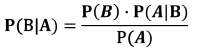

$P(\text{Spam | New message}) = \dfrac{P(\text{Spam})P(\text{New message|Spam})}{P(\text{New message})}$

$P(\text{Ham | New message}) = \dfrac{P(\text{Ham})P(\text{New message|Ham})}{P(\text{New message})}$

**If P(Spam|New Message) > P(Ham|New Message), the sms will be classified as spam.**

## Computing the probability of one-word message: 'money'. Find out if it is spam or ham.

$P(\text{Spam | "money"}) = \dfrac{P(\text{Spam})P(\text{"money"|Spam})}{P(\text{"money"})}$

$P(\text{Ham | "money"}) = \dfrac{P(\text{Ham})P(\text{"money"|Ham})}{P(\text{"money"})}$

We can notice that the fractions have the same denominator. Thus we can ignore the division and compute just the numerator. The results will not be anymore probabilities, but due to this fraction reduction we will need to do less calculations which might be significant for a dataset of 100000 messages.  

The following expression are **directly proportional** expressed by the symbol $\propto$.

$P(\text{Spam | "money"}) \propto  P(\text{Spam})P(\text{"money"|Spam})$ 

$P(\text{Ham | "money"}) \propto  P(\text{Ham})P(\text{"money"|Ham})$ 

### Computing the probability that the new message is a spam.

Probability of having spam messages in the dataset.

$P(\text{Spam}) = \dfrac{\text{number of spam messages}}{\text{total number of messages}}$

In [4]:
sms

,label,text
0,spam,prise money winner
1,spam,winner money gift money
2,ham,I need some money for their gift
3,?,money


In [5]:
p_spam = 2/3

Probability of **the new message given spam**.

$P(\text{"money" | Spam}) = \dfrac{\text{number of times the word "money" occurs in spam messages}}{\text{total number of words in all spam messages}}$

In [7]:
p_money_spam = 3/7
p_money_spam

0.42857142857142855

Now we have all the formula components to compute the probability that the new message is a spam.

In [8]:
spam_new_message = p_spam * p_money_spam
spam_new_message

0.2857142857142857

### Computing the probability that the new message is a ham.

In [ ]:
sms

$P(\text{Ham}) = \dfrac{\text{number of ham messages}}{\text{total number of messages}}$

In [9]:
p_ham = 1/3
p_ham 

0.3333333333333333

$P(\text{"money" | Ham}) = \dfrac{\text{number of times the word "money" occurs in ham messages}}{\text{total number of words in all ham messages}}$

In [10]:
p_money_ham = 1/7
p_money_ham

0.14285714285714285

In [11]:
ham_new_message = p_ham * p_money_ham
ham_new_message

0.047619047619047616

In [12]:
if spam_new_message > ham_new_message:
    print('The new message is spam')
elif spam_new_message < ham_new_message:
    print('The new message is ham')
else:
    print('Needs the human check')

The new message is spam


## Compute the probability for multiple-words message

In [ ]:
new_message = 'money gift money'

In this case we will treat each word in our new message separately.

P(Spam|word_1, word_2, word_3) $\propto$ **P(Spam) P(word_1|Spam) P(word_2|Spam) P(word_3|Spam)**

P(Ham|word_1, word_2, word_3) $\propto$ **P(Ham) P(word_1|Ham) P(word_2|Ham) P(word_3|Ham)**

In [13]:
sms

,label,text
0,spam,prise money winner
1,spam,winner money gift money
2,ham,I need some money for their gift
3,?,money


In [14]:
p_spam

0.6666666666666666

P(Spam|money, gift, money) $\propto$ **P(Spam) P(money|Spam) P(gift|Spam) P(money|Spam)**

P(Ham|money, gift, money) $\propto$ **P(Ham) P(money|Ham) P(gift|Ham) P(money|Ham)**

In [15]:
p_w1_given_spam = 3/7
p_w2_given_spam = 1/7
p_w3_given_spam = 3/7

In [16]:
nm_spam = p_spam * p_w1_given_spam * p_w2_given_spam * p_w3_given_spam
nm_spam

0.017492711370262388

In [ ]:
p_ham

In [17]:
p_w1_given_ham = 1/7
p_w2_given_ham = 1/7
p_w3_given_ham = 1/7

In [18]:
nm_ham = p_ham * p_w1_given_ham * p_w2_given_ham * p_w3_given_ham
nm_ham

0.0009718172983479104

In [19]:
if nm_spam > nm_ham:
    print('The new message is spam')
elif nm_spam < nm_ham:
    print('The new message is ham')
else:
    print('Needs the human check')

The new message is spam


## Compute the probability for multiple-words message that contains new words

In [20]:
sms = pd.DataFrame([['spam', 'prise money winner'],
             ['spam', 'winner money gift money'],
            ['spam', 'call us to get your prise'],
            ['ham', 'i need some money for their gift'],
            ['ham', 'call me'],
                   ['?', 'could you borrow me some money']], columns = ['label', 'text'])
sms

,label,text
0,spam,prise money winner
1,spam,winner money gift money
2,spam,call us to get your prise
3,ham,i need some money for their gift
4,ham,call me
5,?,could you borrow me some money


$P(\text{Spam}) = \dfrac{\text{number of spam messages}}{\text{total number of messages}}$

In [21]:
p_spam = 3/5
p_spam

0.6

$P(\text{word | Spam}) = \dfrac{\text{number of times the specified word occurs in spam messages}}{\text{total number of words in all spam messages}}$

In [22]:
p_w1_given_spam = 0/13
p_w2_given_spam = 0/13
p_w3_given_spam = 0/13
p_w4_given_spam = 0/13
p_w5_given_spam = 0/13 
p_w6_given_spam = 3/13

In [23]:
nm_spam = p_spam * p_w1_given_spam * p_w2_given_spam * p_w3_given_spam * p_w4_given_spam * p_w5_given_spam * p_w6_given_spam
nm_spam

0.0

$P(\text{word | Ham}) = \dfrac{\text{number of times the specified word occurs in ham messages}}{\text{total number of words in all ham messages}}$

In [24]:
p_w1_given_ham = 0/9
p_w2_given_ham = 0/9
p_w3_given_ham = 0/9
p_w4_given_ham = 1/9
p_w5_given_ham = 1/9
p_w6_given_ham = 1/9

In [25]:
nm_ham = p_ham * p_w1_given_ham * p_w2_given_ham * p_w3_given_ham * p_w4_given_ham * p_w5_given_ham * p_w6_given_ham
nm_ham

0.0

To fix the problem we need to use a technique called **additive smoothing**, where we add a smoothing parameter $\alpha\$. This parameter will be introduced in the following formula.

$P(\text{"could" | Spam}) = \dfrac{\text{number of times the word "could" occurs in spam messages}}{\text{total number of words in all spam messages}}$

$P(\text{"could" | Spam}) = \dfrac{\text{number of times the word "could" occurs in spam messages} + \alpha\ }{\text{total number of words in all spam messages} + \alpha\ \times \text{number of unique words in all the messages(both spam and ham)}}$

if $\alpha\$ **= 1**, it is called **Laplace smoothing**

if  $\alpha\$ **< 1**, it is called **Lidstone smoothing**

To avoid a special treatment of the new words we should use the additive smoothing for every word.

In [26]:
p_w1_given_spam = (0 + 1)/(13 + 1*15)
p_w2_given_spam = (0 + 1)/(13 + 1*15)
p_w3_given_spam = (0 + 1)/(13 + 1*15)
p_w4_given_spam = (0 + 1)/(13 + 1*15)
p_w5_given_spam = (0 + 1)/(13 + 1*15)
p_w6_given_spam = (3 + 1)/(13 + 1*15)

In [27]:
nm_spam = p_spam * p_w1_given_spam * p_w2_given_spam * p_w3_given_spam * p_w4_given_spam * p_w5_given_spam * p_w6_given_spam
nm_spam

4.9803865736215334e-09

In [28]:
p_w1_given_ham = (0 + 1)/(9 + 1*15)
p_w2_given_ham = (0 + 1)/(9 + 1*15)
p_w3_given_ham = (0 + 1)/(9 + 1*15)
p_w4_given_ham = (1 + 1)/(9 + 1*15)
p_w5_given_ham = (1 + 1)/(9 + 1*15)
p_w6_given_ham = (1 + 1)/(9 + 1*15)

In [29]:
nm_ham = p_ham * p_w1_given_ham * p_w2_given_ham * p_w3_given_ham * p_w4_given_ham * p_w5_given_ham * p_w6_given_ham
nm_ham

1.3954082361682667e-08

In [30]:
if nm_spam > nm_ham:
    print('The new message is spam')
elif nm_spam < nm_ham:
    print('The new message is ham')
else:
    print('Needs the human check')

The new message is ham


##### Task: Try to classify the same message 'could you borrow me some money' using the Lidstone smoothing parameter.